# DAY1 실습 02 — 분포와 시각화·이상값 후보

In [ ]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

In [ ]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD-AI/data"
csv_path = os.path.join(data_folder, "ai4i2020.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. 분포와 히스토그램

분포(Distribution)는 데이터 값이 **어디에, 얼마나 자주 나타나는지**를 나타낸다. 분포는 다음 세 측면을 함께 살핀다.

| 측면 | 확인할 질문 | 대표적인 통계량·그래프 |
|---|---|---|
| 중심 | 값이 주로 어디에 모여 있는가? | 평균, 중앙값, 최빈값 |
| 퍼짐 | 값이 중심에서 얼마나 흩어져 있는가? | 범위, IQR, 표준편차 |
| 모양 | 대칭인가, 어느 쪽 꼬리가 긴가, 봉우리는 몇 개인가? | 히스토그램, 밀도곡선 |

그래프에서 모양은 관찰할 수 있지만, 모양이 생긴 **원인**까지 그래프만으로 확정할 수는 없다.

### 1-1. 대칭·오른쪽 치우침·왼쪽 치우침

- **대칭에 가까운 분포:** 중심을 기준으로 좌우 모양이 비슷하다.
- **오른쪽 치우침:** 큰 값 방향인 오른쪽 꼬리가 길다.
- **왼쪽 치우침:** 작은 값 방향인 왼쪽 꼬리가 길다.

치우침의 이름은 봉우리가 있는 방향이 아니라 **긴 꼬리가 향하는 방향**으로 정한다.

### 1-2. 분포 예제

분포의 치우침은 평균과 중앙값의 위치, 왜도(skewness)의 부호로 확인할 수 있다.

| 분포 | 평균과 중앙값 | 왜도 |
|---|---|---|
| 대칭 | 평균 ≈ 중앙값 | 0 근처 |
| 오른쪽 치우침 | 평균 > 중앙값 | 양수 |
| 왼쪽 치우침 | 평균 < 중앙값 | 음수 |

In [ ]:
# [예제] 대칭 분포와 좌우로 치우친 분포 비교
# 내용: 세 가지 분포의 평균, 중앙값, 표준편차, 왜도를 비교하고
#       히스토그램으로 분포 모양을 확인한다.


# 1) 분포별 데이터 만들기 (각각 31개)
# [10](리스트) * 3 → 10을 3번 반복하여 [10, 10, 10] 생성

# 대칭 분포: 가운데 값이 많고 양쪽으로 비슷하게 퍼짐
symmetric = (
    [10] + [20]*3 + [30]*7 + [40]*9 +
    [50]*7 + [60]*3 + [70]
)

# 오른쪽 치우침: 작은 값이 많고 큰 값이 일부 있음
# → 오른쪽 꼬리가 길다.
right_skewed = (
    [10]*12 + [15]*8 + [20]*4 + [30]*3 +
    [40]*2 + [65] + [90]
)

# 왼쪽 치우침: 큰 값이 많고 작은 값이 일부 있음
# → 왼쪽 꼬리가 길다.
left_skewed = (
    [90]*12 + [85]*8 + [80]*4 + [70]*3 +
    [60]*2 + [35] + [10]
)


# 2) DataFrame 만들기
data1 = pd.DataFrame({
    "대칭": symmetric,
    "오른쪽 치우침": right_skewed,
    "왼쪽 치우침": left_skewed
})


# 3) 평균, 중앙값, 표준편차, 왜도 계산
#    skew : 왜도. 오른쪽 꼬리가 길면 양수, 왼쪽 꼬리가 길면 음수
summary = pd.DataFrame({
    "평균": data1.mean(),
    "중앙값": data1.median(),
    "표준편차": data1.std(),
    "왜도": data1.skew()
})

display(summary.round(2))

,평균,중앙값,표준편차,왜도
대칭,40.00,40.0,13.66,0.00
오른쪽 치우침,20.81,15.0,17.71,2.68
왼쪽 치우침,79.19,85.0,17.71,-2.68


### **참고: 히스토그램과 `bins` 옵션**

히스토그램(Histogram)은 **숫자 데이터를 여러 구간으로 나누고, 각 구간에 들어 있는 데이터 개수(빈도)를 막대 높이로 나타내는 그래프**이다.

`bins`는 히스토그램의 **구간 개수 또는 구간 경계**를 설정하는 옵션이다.

### **1. `bins=10` : 구간 개수 지정**

```python
data1["대칭"].hist(bins=10)
```

- 데이터의 최솟값과 최댓값을 확인한다.
- 최솟값부터 최댓값까지 같은 너비의 10개 구간으로 나눈다.
- 각 구간에 들어 있는 데이터 개수를 계산하여 막대로 표시한다.

예를 들어 데이터 범위가 10~70이면 구간 너비는 다음과 같다.

`(70 - 10) / 10 = 6`

### **2. `bins=range(0, 101, 10)` : 구간 경계 직접 지정**

```python
data1.hist(bins=range(0, 101, 10))
```

구간 경계를 `0, 10, 20, 30, ..., 100`으로 직접 지정한다.

따라서 0~10, 10~20, ..., 90~100의 **10개 구간**을 만든다.

지정한 범위 밖의 데이터는 히스토그램 빈도 계산에서 제외된다.

### **3. `bins`를 생략하면?**

```python
data1["대칭"].hist()
```

기본적으로 10개 구간으로 나눈다.

| 설정 | 의미 |
|---|---|
| `bins` 생략 | 기본적으로 10개 구간 |
| `bins=5` | 데이터 범위를 같은 너비로 5등분 |
| `bins=10` | 데이터 범위를 같은 너비로 10등분 |
| `bins=range(0, 101, 10)` | 0~100을 10 단위 구간으로 나눔 |

**핵심:** `bins`에 숫자를 지정하면 구간 경계를 자동 계산하고, 구간 경계를 직접 지정하면 해당 경계에 따라 빈도를 계산한다.

여러 분포를 비교할 때는 같은 구간 경계를 사용하는 것이 좋다.

공식 문서: [Pandas Series.hist()](https://pandas.pydata.org/docs/reference/api/pandas.Series.hist.html) · [Pandas DataFrame.hist()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html)

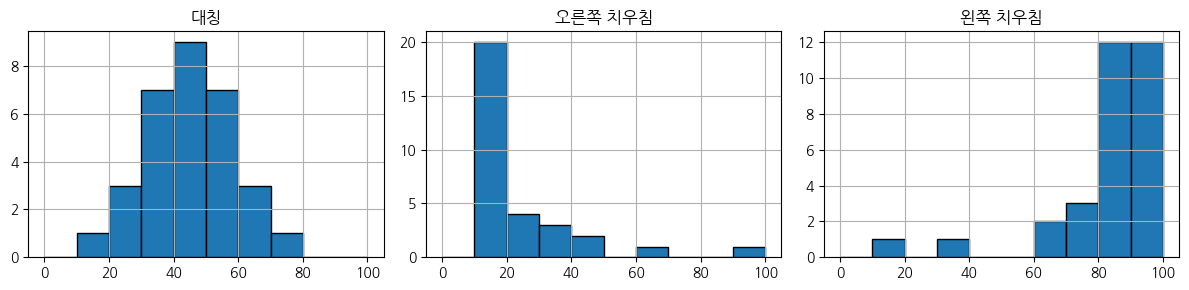

In [ ]:
# [예제] 세 분포의 히스토그램 비교
# hist : 히스토그램. DataFrame 에 쓰면 숫자 열마다 하나씩 그린다
# 같은 구간(0~100, 10 단위)을 써야 세 분포의 모양을 바로 비교할 수 있다

data1.hist(
    bins=range(0, 101, 10),  # bins : 0~100을 10 단위로 나눔
    figsize=(12, 3),         # figsize : 전체 그래프 크기 (가로, 세로)
    layout=(1, 3),           # layout : 1행 3열로 배치
    edgecolor="black"        # edgecolor : 막대 테두리 색
)

plt.tight_layout()           # tight_layout : 그래프 간격 자동 조정
plt.show()                   # show : 그래프 표시

가로축은 값의 구간(10 단위), 세로축은 그 구간에 속한 값의 개수(도수)이다. 가장 높은 막대가 있는 구간을 봉우리, 봉우리에서 한쪽으로 길게 이어지는 낮은 막대들을 꼬리라고 한다.

### 1-3. AI4I 회전속도 히스토그램

x축은 회전속도 구간(rpm), y축은 해당 구간의 관측 건수이다. 막대그래프의 x축은 개별 범주라는 점과 구분한다.

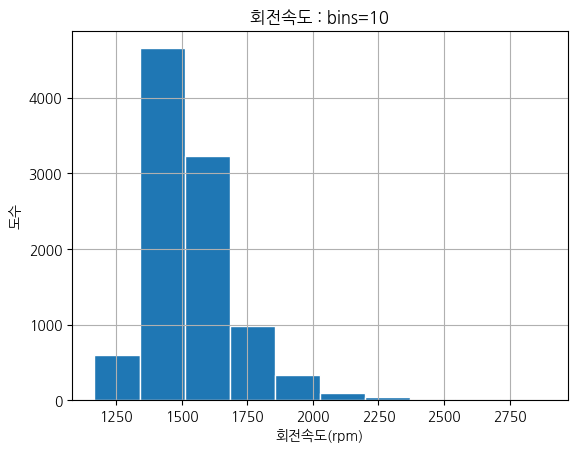

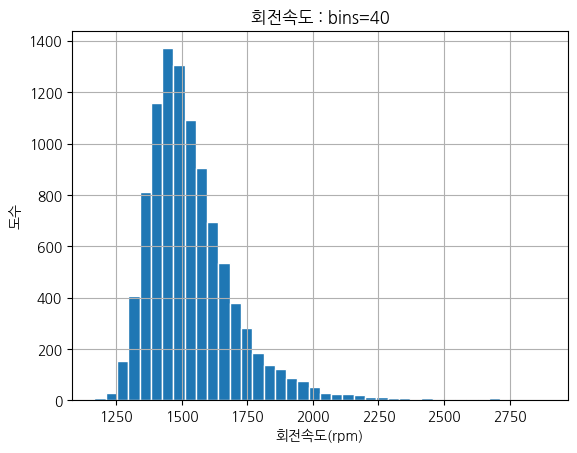

In [ ]:
# [예제] 회전속도 히스토그램의 구간 수 비교
# 문제: bins=10과 bins=40으로 설정했을 때
#       데이터가 모인 구간과 오른쪽 꼬리의 차이를 비교한다.
#       hist() 는 결측값을 빼고 그린다.

speed = data["Rotational speed [rpm]"]


# 1) 10개 구간
speed.hist(bins=10, edgecolor="white")
plt.title("회전속도 : bins=10")       # title : 그래프 제목
plt.xlabel("회전속도(rpm)")            # xlabel : 가로축 이름
plt.ylabel("도수")                     # ylabel : 세로축 이름
plt.show()


# 2) 40개 구간
speed.hist(bins=40, edgecolor="white")
plt.title("회전속도 : bins=40")
plt.xlabel("회전속도(rpm)")
plt.ylabel("도수")
plt.show()

가로축은 회전속도 구간(rpm), 세로축은 그 구간에 속한 기록 수(도수)이다. 구간 수(`bins`)가 너무 적으면 분포의 모양이 뭉개지고, 너무 많으면 막대가 들쭉날쭉해진다.

## 2. 박스플롯과 IQR 기준 이상값 후보

박스플롯(Box plot)은 Q1, 중앙값, Q3와 IQR을 이용해 분포를 압축하여 보여 준다.

- **상자:** Q1부터 Q3까지이며 가운데 50%의 폭을 나타낸다.
- **상자 안 선:** 중앙값이다.
- **수염:** 1.5 × IQR 경계 안에 실제로 존재하는 가장 바깥 관측값까지 이어진다.
- **수염 밖 점:** 통계적 이상값 후보다.

수염 끝은 IQR 경계값 자체가 아니며 항상 최솟값·최댓값인 것도 아니다.

### 2-1. IQR 기준 이상값 후보를 확인하는 이유

IQR은 Q1과 Q3 사이, 즉 가운데 50%의 퍼짐인 `Q3 - Q1`이다. 평균과 표준편차를 사용하는 방법과 달리 **사분위수**를 기준으로 한다.

- 하한 = Q1 − 1.5 × IQR
- 상한 = Q3 + 1.5 × IQR

하한보다 작거나 상한보다 큰 값을 **IQR 기준 이상값 후보**로 표시한다. 가운데 50%에 포함된 값의 수를 세는 것이 아니라, 이 경계 밖의 값을 세는 것이다.

1.5는 가운데 구간의 폭에 비해 멀리 떨어진 값을 표시하는 널리 쓰이는 관례적 배수이다. 오류나 삭제 대상을 확정하는 절대 기준은 아니다.

In [ ]:
# [예제] IQR을 이용한 회전속도 이상값 탐지
# 내용: 회전속도의 Q1, Q3, IQR을 계산하고,
#       정상 범위를 벗어나는 이상값 후보의 개수를 확인한다.


# 1) 회전속도 열 선택
#    Rotational speed [rpm] : 설비의 분당 회전속도

speed = data["Rotational speed [rpm]"]


# 2) Q1(25%)과 Q3(75%) 계산
#    quantile([0.25, 0.75]) : 두 사분위수를 한 번에 계산
#    q1 : 하위 25% 지점
#    q3 : 하위 75% 지점

q1, q3 = speed.quantile([0.25, 0.75])


# 3) IQR(사분위범위) 계산
#    IQR = Q3 - Q1
#    데이터 가운데 50%의 퍼짐 정도를 나타낸다.

iqr = q3 - q1


# 4) 이상값 판단 기준(하한·상한) 계산
#    하한 = Q1 - 1.5 × IQR
#    상한 = Q3 + 1.5 × IQR
#    이 범위를 벗어나면 이상값 후보로 판단한다.

lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr


# 5) 이상값 후보 찾기
#    speed < lower : 하한보다 작은 값
#    speed > upper : 상한보다 큰 값
#    | : 두 조건 중 하나라도 참이면 True
#    iqr_mask : 이상값 후보는 True, 나머지는 False

iqr_mask = (speed < lower) | (speed > upper)


# 6) 결과 출력
#    round(값, 1) : 소수점 첫째 자리까지 반올림
#    iqr_mask.sum() : True를 1로 계산하여 이상값 후보 개수를 센다.

print("하한·상한(rpm):", round(lower, 1), round(upper, 1))
print("IQR 기준 이상값 후보 수:", iqr_mask.sum())

하한·상한(rpm): 1139.5 1895.5
IQR 기준 이상값 후보 수: 418


### **`plot.box()`의 의미**

`plot.box()`는 **데이터의 중앙값, 사분위수, 퍼짐 정도, 이상값 후보를 상자 모양으로 나타내는 그래프**이다.

박스플롯(Boxplot)을 보면 데이터가 어느 구간에 모여 있는지, 이상값 후보가 있는지 확인할 수 있다.

### **기본 사용법**

```python
speed.plot.box(whis=1.5, showmeans=True)
```

### **주요 옵션**

| 옵션 | 기본값 | 의미 |
|---|---|---|
| `whis` | `1.5` | IQR을 기준으로 수염의 범위 결정 |
| `showmeans` | `False` | `True`이면 평균도 표시 |
| `showfliers` | `True` | `False`이면 이상값 후보 점을 숨김 |

### **박스플롯의 구성 요소**

- **Q1 (1사분위수)**: 하위 25% 지점
- **중앙값(Q2)**: 하위 50% 지점
- **Q3 (3사분위수)**: 하위 75% 지점
- **상자**: Q1부터 Q3까지, 가운데 50%의 범위
- **수염**: 기본적으로 Q1 − 1.5×IQR부터 Q3 + 1.5×IQR 사이에 있는 관측값 중 가장 바깥 값까지 표시
- **상자 밖의 점**: 수염 범위를 벗어난 이상값 후보

`showfliers=False`는 이상값 후보를 화면에서 숨기는 옵션

### **히스토그램과 박스플롯 비교**

| 구분 | 히스토그램 | 박스플롯 |
|---|---|---|
| 주요 목적 | 데이터의 분포 모양 확인 | 중앙값, 퍼짐, 이상값 후보 확인 |
| 핵심 설정 | `bins` | `whis` |
| 코드 | `Series.hist()` | `Series.plot.box()` |

**핵심:** 히스토그램은 구간별 빈도를 보여주고, 박스플롯은 사분위수와 이상값 후보를 보여준다.

공식 문서: [Pandas Series.plot.box()](https://pandas.pydata.org/docs/reference/api/pandas.Series.plot.box.html) · [Matplotlib boxplot() 옵션](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html)

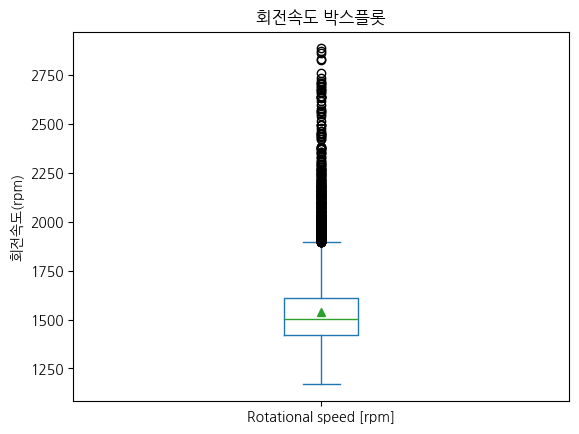

In [ ]:
# [예제] 회전속도 박스플롯
# plot.box : 박스플롯
#   whis : 수염 기준 (IQR 의 1.5배)
#   showmeans : True 이면 평균을 초록 삼각형으로 표시

speed = data["Rotational speed [rpm]"]

speed.plot.box(whis=1.5, showmeans=True)
plt.title("회전속도 박스플롯")
plt.ylabel("회전속도(rpm)")
plt.show()

상자는 Q1 ~ Q3(가운데 50%), 상자 안 선은 중앙값, 삼각형은 평균, 수염 밖의 점은 IQR 기준 이상값 후보이다. 이상값 후보가 한쪽에만 몰려 있으면 그 방향으로 치우친 분포이다.

## **3. 정규분포와 z-score**

정규분포는 **평균을 중심으로 좌우가 대칭인 종 모양의 분포**이다.

- **평균(mean)**: 데이터의 중심을 나타낸다.
- **표준편차(std)**: 데이터가 평균을 중심으로 얼마나 퍼져 있는지 나타낸다.

### **z-score(표준점수)의 의미**

z-score는 **관측값이 평균에서 표준편차의 몇 배만큼 떨어져 있는지** 나타내는 값이다.

### **계산 공식**
z-score = (관측값 - 평균) / 표준편차

| z-score | 의미 |
|---|---|
| z = 0 | 평균과 같은 위치 |
| z = 1 | 평균보다 표준편차 1배만큼 높음 |
| z = −1 | 평균보다 표준편차 1배만큼 낮음 |
| z = 2 | 평균보다 표준편차 2배만큼 높음 |
| z = −2 | 평균보다 표준편차 2배만큼 낮음 |

### **계산 예시**

평균이 50이고 표준편차가 10이라고 가정한다.

| 관측값 | 계산 | z-score | 해석 |
|---|---|---:|---|
| 30 | (30 − 50) ÷ 10 | −2 | 평균보다 표준편차 2배만큼 낮음 |
| 50 | (50 − 50) ÷ 10 | 0 | 평균과 같음 |
| 70 | (70 − 50) ÷ 10 | 2 | 평균보다 표준편차 2배만큼 높음 |

**z-score의 절댓값이 클수록 평균에서 멀리 떨어져 있다는 의미**이다.

### **z-score로 이상값 후보 확인하기**

평균에서 크게 벗어난 값을 이상값 후보로 확인할 때 z-score를 활용할 수 있다.

예를 들어 `|z| > 3`을 기준으로 정하면 평균에서 표준편차 3배보다 더 멀리 떨어진 값을 이상값 후보로 분류한다.

다만 이 기준이 모든 데이터에 적절한 것은 아니므로, 분포의 모양과 분석 목적을 함께 확인해야 한다.



**핵심:** z-score는 데이터의 원래 단위를 제거하고, 평균으로부터 떨어진 거리를 표준편차 기준으로 비교하는 방법이다.

In [ ]:
# [예제] z-score 계산
# 평균 50, 표준편차 10이라고 가정한다.

values = pd.Series([30, 50, 70])

mean_value = 50
std_value = 10

# z-score = (관측값 - 평균) / 표준편차
z_scores = (values - mean_value) / std_value

print("z-score:", z_scores.tolist())
# [-2.0, 0.0, 2.0]

z-score: [-2.0, 0.0, 2.0]


In [ ]:
# [실습]
# 회전속도의 평균(mean)과 표준편차(std, ddof=1)를 구해 각 값의 z-score를 계산하고, head()로 처음 5개 값을 출력하시오
# 계산한 z-score 는 z_speed 라는 이름에 담는다

speed = data["Rotational speed [rpm]"]



### `|z| > 3` 기준의 근거
정규분포에서는 약 99.7%의 값이 평균 ±3 표준편차 범위에 위치한다.

따라서 `|z| > 3`은 평균에서 표준편차 3배보다 더 멀리 떨어진 값을 찾는 대표적인 참고 기준이다.

`abs()`는 절댓값을 계산하며, 평균보다 높은 값과 낮은 값을 모두 확인할 때 사용한다.

**주의할 점**
- z-score는 정규분포가 아닌 데이터에서도 계산할 수 있다.
- 다만 비대칭 분포에서는 정규분포의 99.7% 규칙을 그대로 적용할 수 없다.
- 극단값이 평균과 표준편차에 영향을 주어 이상값 판단 결과가 달라질 수 있다.
- `|z| > 3`은 이상값 후보를 찾는 기준이지, 오류나 고장으로 확정하는 기준은 아니다.

In [ ]:
# [예제]
# 평균에서 표준편차 3배보다 더 멀리 떨어진 회전속도의 z-score 기준 이상값 후보는 몇 건인가?
# 이상값 후보 조건은 z_mask 라는 이름에 담는다


z_mask = z_speed.abs() > 3
print("z-score 기준 이상값 후보:", z_mask.sum())

#  data.loc[행 선택 조건, 열 선택 목록]
display(data.loc[z_mask, ["Rotational speed [rpm]"]])

z-score 기준 이상값 후보: 164


,Rotational speed [rpm]
50,2861
194,2678
298,2129
305,2129
344,2448
...,...
9758,2271
9832,2118
9849,2312
9865,2450


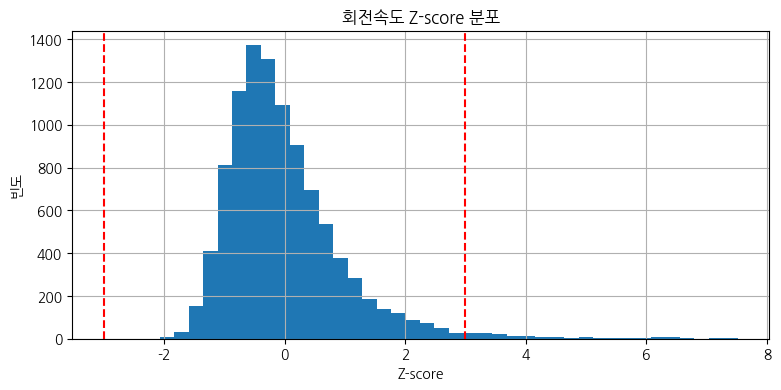

이상값 후보: 164 건


In [ ]:
# 회전속도 z-score 분포
# z_speed.hist : 앞에서 계산한 z-score 10,000개의 히스토그램. figsize=(가로, 세로) 그림 크기
z_speed.hist(bins=40, figsize=(9, 4))

# 이상값 기준선 : axvline 은 지정한 x 위치에 세로선을 긋는다
plt.axvline(-3, color="red", linestyle="--")   # z = −3
plt.axvline(3, color="red", linestyle="--")    # z = +3

plt.title("회전속도 Z-score 분포")
plt.xlabel("Z-score")
plt.ylabel("빈도")
plt.show()

# abs() 로 절댓값을 구해 3 보다 큰 값(점선 바깥)의 개수를 센다
print("이상값 후보:", (z_speed.abs() > 3).sum(), "건")

가로축은 z-score, 세로축은 기록 수이다. 빨간 점선(−3, +3) 바깥에 있는 값이 z-score 기준 이상값 후보이다.

## **4. 왜도와 초과첨도**

왜도와 초과첨도는 **데이터 분포의 모양을 수치로 확인하는 통계량**이다.

| 지표 | 의미 | 해석 |
|---|---|---|
| **왜도(Skewness)** | 분포가 좌우로 얼마나 비대칭인지 나타냄 | 양수: 오른쪽 꼬리가 김 / 음수: 왼쪽 꼬리가 김 |
| **초과첨도(Excess Kurtosis)** | 정규분포와 비교하여 꼬리가 얼마나 두껍거나 얇은지 나타냄 | 양수: 상대적으로 두꺼운 꼬리 / 음수: 상대적으로 얇은 꼬리 |

### **Pandas에서 계산하기**

```python
print(data["Rotational speed [rpm]"].skew())  # 왜도
print(data["Rotational speed [rpm]"].kurt())  # 초과첨도
```

### **해석 시 주의사항**

- 왜도가 0에 가까우면 좌우 대칭에 가까운 분포일 수 있다.
- 초과첨도가 0에 가까우면 정규분포와 비슷한 첨도 특성을 가질 수 있다.
- Pandas의 `kurt()`는 **정규분포의 이론적 초과첨도를 0으로 설정한 방식**을 사용한다.
- 두 값이 모두 0에 가까워도 정규분포라는 것을 증명하지는 않는다.
- 왜도와 초과첨도는 극단값의 영향을 받으므로 히스토그램과 함께 확인하는 것이 좋다.

왜도는 분포의 좌우 비대칭을, 초과첨도는 정규분포 대비 꼬리의 특성을 파악하는 데 도움을 준다.

공식 문서: [Pandas skew()](https://pandas.pydata.org/docs/reference/api/pandas.Series.skew.html) · [Pandas kurt()](https://pandas.pydata.org/docs/reference/api/pandas.Series.kurt.html) · [NIST 왜도와 첨도](https://itl.nist.gov/div898/handbook/eda/section3/eda35b.htm)

In [ ]:
# [실습]
# 회전속도와 Torque의 왜도 및 초과첨도는 각각 얼마인가?



In [ ]:
# 왜도 숫자를 히스토그램 모양과 함께 확인한다
data[["Rotational speed [rpm]", "Torque [Nm]"]].hist(
    bins=30,               # 데이터 범위를 각각 30개 구간으로 분할
    figsize=(12, 4),       # 그래프 크기
    layout=(1, 2),         # 1행 2열 배치
    edgecolor="black"      # 막대 테두리
)

plt.tight_layout()
plt.show()

왼쪽은 회전속도, 오른쪽은 토크의 히스토그램이다. 왜도가 양수이면 오른쪽 꼬리가, 음수이면 왼쪽 꼬리가 길다. 초과첨도가 클수록 정규분포보다 꼬리 쪽에 값이 많다.

## 5. IQR 기준과 z-score 기준의 비교

| 방법 | 사용하는 기준 |
|---|---|
| IQR | Q1·Q3와 가운데 50%의 퍼짐 |
| z-score | 평균과 표준편차 |

두 방법은 중심부에서 멀리 떨어진 관측값을 확인한다는 목적은 같지만 사용하는 기준이 다르다. 따라서 같은 데이터에서도 이상값 후보 수가 달라질 수 있다. 치우친 분포에서는 꼬리 쪽 큰 값들이 평균과 표준편차를 키우므로, z-score 기준의 경계가 IQR 기준보다 멀어지는 경우가 많다.


In [ ]:
# [예제]
# 같은 회전속도 자료에서 IQR 기준 이상값 후보와 z-score 기준 이상값 후보는 각각 몇 건인가?
# 2절 예제의 iqr_mask, 3절 예제의 z_mask 를 사용한다 (이상값 후보이면 True)
pd.Series({
    "IQR 기준 이상값 후보": int(iqr_mask.sum()),
    "z-score 기준 이상값 후보": int(z_mask.sum()),
})


### 직접 해보기

Torque [Nm]의 히스토그램과 박스플롯을 그린다.

In [ ]:
# [실습]
# Torque [Nm]의 히스토그램과 박스플롯을 그리고, 분포 모양과 이상값 후보를 확인하시오.

torque = data["Torque [Nm]"]



### 직접 해보기

Torque [Nm]의 IQR 경계와 이상값 후보 수를 계산한다.

In [ ]:
# [실습]
# Torque [Nm]의 IQR 경계와 이상값 후보 수를 계산하시오.

torque = data["Torque [Nm]"]

